In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

In [43]:
train = pd.read_csv("solicitudes_train.csv")
test = pd.read_csv("solicitudes_test.csv")
banco = pd.read_csv("comportamiento_bancario.csv")

print("=== DIMENSIONES ===")
print(f"Train: {train.shape}")
print(f"Test:  {test.shape}")
print(f"Comportamiento Bancario: {banco.shape}")

=== DIMENSIONES ===
Train: (32416, 8)
Test:  (3061, 7)
Comportamiento Bancario: (661139, 4)


In [44]:
def check_health(df, name):
    print(f"\n--- Diagnóstico: {name} ---")
    print(f"Duplicados directos: {df.duplicated().sum()}")
    nulls = df.isnull().sum()
    nulls_pct = (nulls / len(df)) * 100
    health_df = pd.DataFrame(
        {
            "Nulos": nulls,
            "Porcentaje (%)": nulls_pct.round(2),
            "Tipo": df.dtypes,
        }
    )
    print(health_df[health_df["Nulos"] > 0])
    if nulls.sum() == 0:
        print(">> No hay valores nulos.")


check_health(train, "Solicitudes Train")
check_health(test, "Solicitudes Test")
check_health(banco, "Comportamiento Bancario")


--- Diagnóstico: Solicitudes Train ---
Duplicados directos: 0
Empty DataFrame
Columns: [Nulos, Porcentaje (%), Tipo]
Index: []
>> No hay valores nulos.

--- Diagnóstico: Solicitudes Test ---
Duplicados directos: 0
Empty DataFrame
Columns: [Nulos, Porcentaje (%), Tipo]
Index: []
>> No hay valores nulos.

--- Diagnóstico: Comportamiento Bancario ---
Duplicados directos: 0
Empty DataFrame
Columns: [Nulos, Porcentaje (%), Tipo]
Index: []
>> No hay valores nulos.


In [ ]:
# conversion de Fechas
train["Fecha_Solicitud"] = pd.to_datetime(train["Fecha_Solicitud"])
test["Fecha_Solicitud"] = pd.to_datetime(test["Fecha_Solicitud"])
banco["Mes_Referencia"] = pd.to_datetime(banco["Mes_Referencia"])



# valores anomalos o negativos
assert (train["Monto_Solicitado"] > 0).all(), "Hay montos negativos o en cero."
assert (train["Ingreso_Mensual"] >= 0).all(), (
    "Hay ingresos mensuales negativos."
)
assert (banco["Dias_Atraso_Otras_Deudas"] >= 0).all(), (
    "Hay días de atraso negativos."
)

In [ ]:
usuarios_train = set(train["ID_Usuario"])
usuarios_test = set(test["ID_Usuario"])
usuarios_banco = set(banco["ID_Usuario"])

print("\n=== COBERTURA DE COMPORTAMIENTO BANCARIO ===")
print(
    f"Usuarios de Train presentes en banco: {len(usuarios_train.intersection(usuarios_banco))} / {len(usuarios_train)} ({len(usuarios_train.intersection(usuarios_banco))/len(usuarios_train)*100:.1f}%)"
)
print(
    f"Usuarios de Test presentes en banco:  {len(usuarios_test.intersection(usuarios_banco))} / {len(usuarios_test)} ({len(usuarios_test.intersection(usuarios_banco))/len(usuarios_test)*100:.1f}%)"
)

# cantidad de meses de historial disponible por usuario
historial_meses = (
    banco.groupby("ID_Usuario")["Mes_Referencia"].count().rename("num_meses")
)
print("\nDistribución de meses de historial por cliente:")
print(historial_meses.describe().round(1))



=== COBERTURA DE COMPORTAMIENTO BANCARIO ===
Usuarios de Train presentes en banco: 18548 / 18548 (100.0%)
Usuarios de Test presentes en banco:  3061 / 3061 (100.0%)

Distribución de meses de historial por cliente:
count    28993.0
mean        22.8
std          1.1
min         17.0
25%         22.0
50%         23.0
75%         24.0
max         24.0
Name: num_meses, dtype: float64



=== BALANCE DE CLASES ===
Pagados (1): 84.05% | Default (0): 15.95%


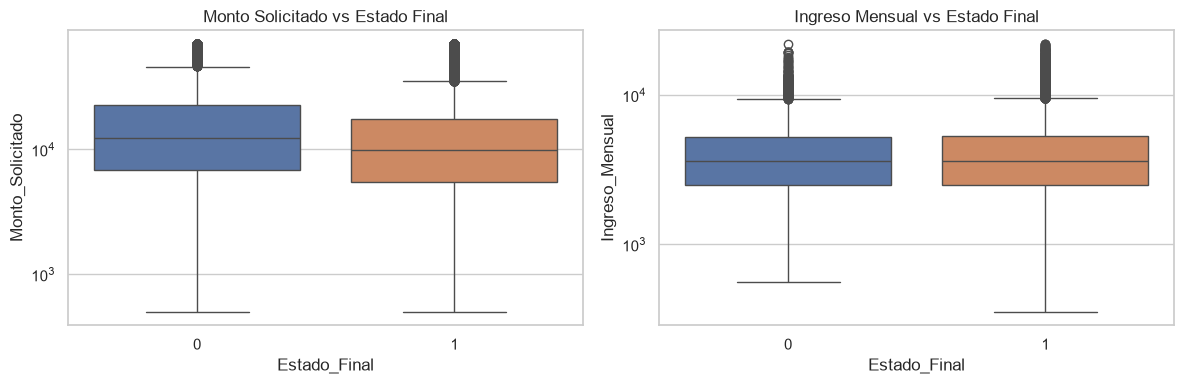

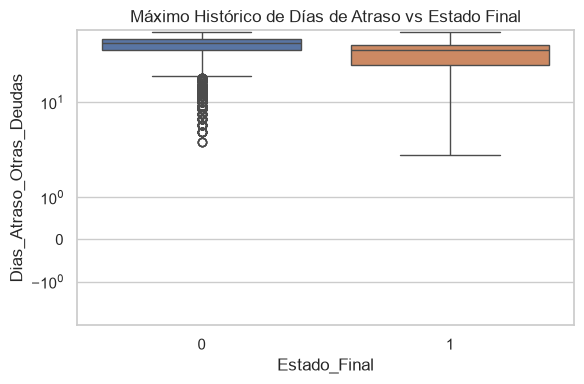


=== TASA DE DEFAULT POR MOTIVO ===
                  total  tasa_default
Motivo_Prestamo                      
Negocio          261700         19.37
Vehiculo         425600         17.39
Otros            397300         17.09
Consumo          904900         16.32
Salud            288400         14.39
Vivienda         576100         14.06
Educacion        387600         14.01


In [ ]:
# tasa base de default
tasa_pago = train["Estado_Final"].mean()
tasa_default = 1 - tasa_pago
print(f"\n=== BALANCE DE CLASES ===")
print(f"Pagados (1): {tasa_pago*100:.2f}% | Default (0): {tasa_default*100:.2f}%")

#distribucion de monto e ingreso segun default
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
sns.boxplot(
    data=train,
    x="Estado_Final",
    y="Monto_Solicitado",
    hue="Estado_Final",
    legend=False,
)
plt.title("Monto Solicitado vs Estado Final")
plt.yscale("log")

plt.subplot(1, 2, 2)
sns.boxplot(
    data=train,
    x="Estado_Final",
    y="Ingreso_Mensual",
    hue="Estado_Final",
    legend=False,
)
plt.title("Ingreso Mensual vs Estado Final")
plt.yscale("log")
plt.tight_layout()
plt.show()

# atraso historico vs default
max_atrasos = (
    banco.groupby("ID_Usuario")["Dias_Atraso_Otras_Deudas"].max().reset_index()
)
merged_eda = train.merge(max_atrasos, on="ID_Usuario", how="left")

plt.figure(figsize=(6, 4))
sns.boxplot(
    data=merged_eda,
    x="Estado_Final",
    y="Dias_Atraso_Otras_Deudas",
    hue="Estado_Final",
    legend=False,
)
plt.title("Máximo Historico de Dias de Atraso vs Estado Final")
plt.yscale("symlog")
plt.tight_layout()
plt.show()

# motivo del prestamo vs tasa de default
print("\n=== TASA DE DEFAULT POR MOTIVO ===")
if "Motivo_Prestamo" in train.columns:
    motivo_stats = (
        train.groupby("Motivo_Prestamo")
        .agg(
            total=("Estado_Final", "count"),
            tasa_default=("Estado_Final", lambda x: 1 - x.mean()),
        )
        .sort_values(by="tasa_default", ascending=False)
    )
    print((motivo_stats * 100).round(2))

In [ ]:
# calcular el total de mora, mora severa y saldo promedio general
agg_hist = banco.groupby("ID_Usuario").agg(
    Total_Meses_Mora=("Dias_Atraso_Otras_Deudas", lambda x: (x > 0).sum()),
    Meses_Mora_Severa_30d=("Dias_Atraso_Otras_Deudas", lambda x: (x >= 30).sum()),
    saldo_promedio=("Saldo_Promedio_Mensual", "mean")
).reset_index()

def preparar_dataset_final(df_solicitudes, df_banco_features):
    # Cruzar datos base con las 3 variables de banco
    df = df_solicitudes.merge(df_banco_features, on="ID_Usuario", how="left")
    
    # agregar carga financiera
    df["Carga_Financiera"] = df["Monto_Solicitado"] / (df["Ingreso_Mensual"] + 1)
    
    # Asegurar que el algoritmo entienda que es una categoría
    if "Motivo_Prestamo" in df.columns:
        df["Motivo_Prestamo"] = df["Motivo_Prestamo"].astype("category")
        
    return df

train_prep = preparar_dataset_final(train, agg_hist)
test_prep = preparar_dataset_final(test, agg_hist)

In [49]:
train_prep.head()

,ID_Solicitud,ID_Usuario,Monto_Solicitado,Tasa_Interes,Ingreso_Mensual,Motivo_Prestamo,Fecha_Solicitud,Estado_Final,Total_Meses_Mora,Meses_Mora_Severa_30d,saldo_promedio,Carga_Financiera
0,1,12698,7900,0.2333,4461,Consumo,2025-04-01,1,22,0,3567.364783,1.770506
1,2,20744,17400,0.2507,3889,Vivienda,2025-12-01,1,22,2,6070.002273,4.473008
2,3,6830,8600,0.2368,4035,Vehiculo,2025-06-01,0,22,4,168.037273,2.130823
3,4,5722,13300,0.2826,4018,Vehiculo,2025-07-01,1,7,1,7564.528696,3.309281
4,5,24719,6600,0.2314,3357,Otros,2025-01-01,1,13,1,3504.671304,1.965456


In [ ]:

#Agregados del historial bancario usando solo meses previos a la solicitud
def features_banco(sol, banco):
    
    m = sol[["ID_Solicitud", "ID_Usuario", "Fecha_Solicitud"]].merge(banco, on="ID_Usuario")
    m = m[m["Mes_Referencia"] < m["Fecha_Solicitud"]].copy()
    m["lag"] = (m["Fecha_Solicitud"].dt.year - m["Mes_Referencia"].dt.year) * 12 + (
        m["Fecha_Solicitud"].dt.month - m["Mes_Referencia"].dt.month
    )
    d = m["Dias_Atraso_Otras_Deudas"]
    m["mora"], m["m30"], m["m60"] = d > 0, d >= 30, d >= 60

    out = m.groupby("ID_Solicitud").agg(
        n_meses=("lag", "count"),
        atraso_mean=("Dias_Atraso_Otras_Deudas", "mean"),
        atraso_max=("Dias_Atraso_Otras_Deudas", "max"),
        atraso_std=("Dias_Atraso_Otras_Deudas", "std"),
        pct_mora=("mora", "mean"),
        pct_m30=("m30", "mean"),
        pct_m60=("m60", "mean"),
        saldo_mean=("Saldo_Promedio_Mensual", "mean"),
        saldo_std=("Saldo_Promedio_Mensual", "std"),
        saldo_min=("Saldo_Promedio_Mensual", "min"),
    )
    # ventanas recientes
    for w in (3, 6):
        r = m[m["lag"] <= w].groupby("ID_Solicitud")
        out[f"atraso_mean_{w}m"] = r["Dias_Atraso_Otras_Deudas"].mean()
        out[f"atraso_max_{w}m"] = r["Dias_Atraso_Otras_Deudas"].max()
        out[f"saldo_mean_{w}m"] = r["Saldo_Promedio_Mensual"].mean()
    # ultimo mes
    last = m[m["lag"] == 1].set_index("ID_Solicitud")
    out["atraso_ult"] = last["Dias_Atraso_Otras_Deudas"]
    out["saldo_ult"] = last["Saldo_Promedio_Mensual"]
    # Tendencias / volatilidad
    out["tend_atraso"] = out["atraso_mean_3m"] - out["atraso_mean"]
    out["tend_saldo"] = out["saldo_mean_3m"] / (out["saldo_mean"] + 1)
    out["saldo_cv"] = out["saldo_std"] / (out["saldo_mean"] + 1)
    return out.reset_index()


def construir_dataset(sol, banco):
    df = sol.merge(features_banco(sol, banco), on="ID_Solicitud", how="left")
    #  capacidad de pago
    df["Carga_Financiera"] = df["Monto_Solicitado"] / (df["Ingreso_Mensual"] + 1)
    df["cuota_aprox"] = df["Monto_Solicitado"] * (1 + df["Tasa_Interes"]) / 12
    df["ratio_cuota_ingreso"] = df["cuota_aprox"] / (df["Ingreso_Mensual"] + 1)
    df["saldo_vs_ingreso"] = df["saldo_mean"] / (df["Ingreso_Mensual"] + 1)
    df["monto_vs_saldo"] = df["Monto_Solicitado"] / (df["saldo_mean"] + 1)
    # transfo
    df["log_monto"] = np.log1p(df["Monto_Solicitado"])
    df["log_ingreso"] = np.log1p(df["Ingreso_Mensual"])
    df["mes_sol"] = df["Fecha_Solicitud"].dt.month
    
    #df = pd.get_dummies(df, columns=["Motivo_Prestamo"], prefix="Motivo", dtype=int)
    df["Motivo_Prestamo"] = df["Motivo_Prestamo"].astype("category")
    return df


train_prep = construir_dataset(train, banco)
test_prep = construir_dataset(test, banco)


cats = train_prep["Motivo_Prestamo"].cat.categories
test_prep["Motivo_Prestamo"] = pd.Categorical(test_prep["Motivo_Prestamo"], categories=cats)

COLS_EXCLUIR = ["ID_Solicitud", "ID_Usuario", "Fecha_Solicitud", "Estado_Final"]
features_all = [c for c in train_prep.columns if c not in COLS_EXCLUIR]
print(f"Total de features generadas: {len(features_all)}")
train_prep[features_all].head()

Total de features generadas: 33


,Monto_Solicitado,Tasa_Interes,Ingreso_Mensual,Motivo_Prestamo,n_meses,atraso_mean,atraso_max,atraso_std,pct_mora,pct_m30,...,tend_saldo,saldo_cv,Carga_Financiera,cuota_aprox,ratio_cuota_ingreso,saldo_vs_ingreso,monto_vs_saldo,log_monto,log_ingreso,mes_sol
0,7900,0.2333,4461,Consumo,14,4.857143,25,6.175101,0.928571,0.000000,...,0.949922,0.120177,1.770506,811.922500,0.181964,0.828155,2.137315,8.974745,8.403352,4
1,17400,0.2507,3889,Vivienda,21,8.809524,56,15.616078,1.000000,0.095238,...,1.032434,0.121940,4.473008,1813.515000,0.466199,1.536364,2.910937,9.764283,8.266164,12
2,8600,0.2368,4035,Vehiculo,15,20.733333,57,13.333452,1.000000,0.200000,...,0.909891,0.097994,2.130823,886.373333,0.219617,0.044245,47.890942,9.059634,8.303009,6
3,13300,0.2826,4018,Vehiculo,18,0.944444,4,1.551933,0.333333,0.000000,...,1.035718,0.128998,3.309281,1421.548333,0.353707,1.888369,1.752223,9.495594,8.298788,7
4,6600,0.2314,3357,Otros,12,3.750000,32,9.006311,0.583333,0.083333,...,0.844114,0.143641,1.965456,677.270000,0.201689,1.158016,1.696825,8.794976,8.119101,1


AUC validación (todas las features): 0.8420


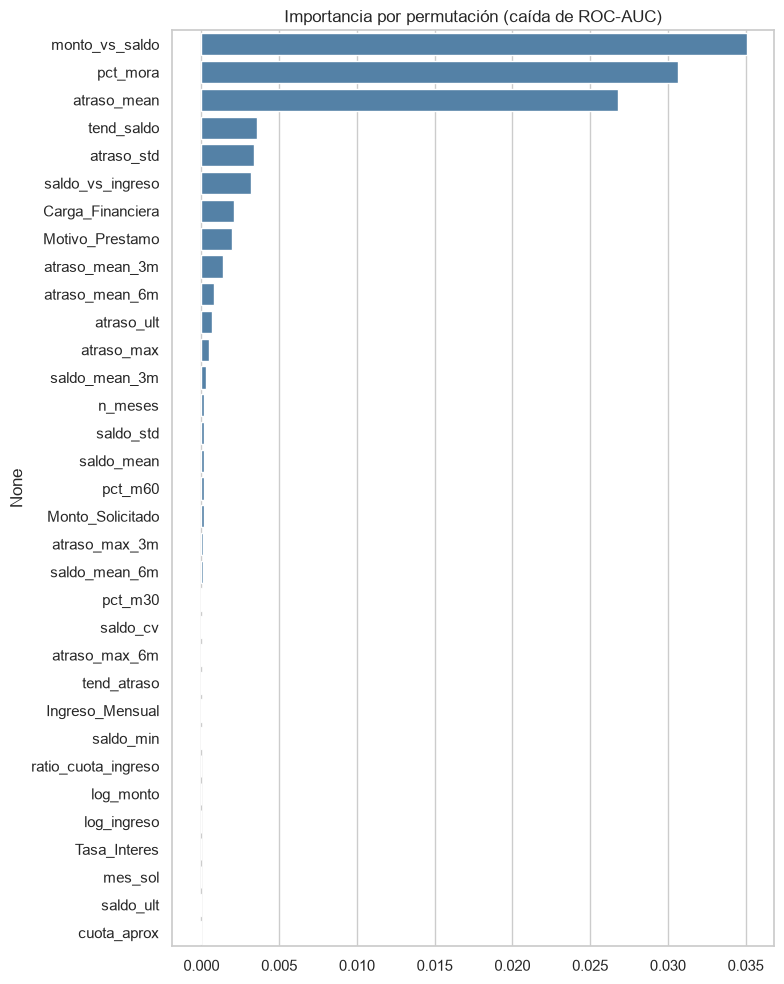

In [ ]:
# Variables representativas 


from pandas.core.arrays import categorical
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.metrics import roc_auc_score

X_all, y_all = train_prep[features_all], train_prep["Estado_Final"]
Xtr, Xv, ytr, yv = train_test_split(X_all, y_all, test_size=0.2, stratify=y_all, random_state=42)

hgb = HistGradientBoostingClassifier(categorical_features="from_dtype" ,learning_rate=0.05, max_iter=300, max_depth=4, random_state=42)
hgb.fit(Xtr, ytr)
print(f"AUC validación (todas las features): {roc_auc_score(yv, hgb.predict_proba(Xv)[:, 1]):.4f}")

pi = permutation_importance(hgb, Xv, yv, scoring="roc_auc", n_repeats=5, random_state=42)
importancias = pd.Series(pi.importances_mean, index=features_all).sort_values(ascending=False)

plt.figure(figsize=(8, 10))
sns.barplot(x=importancias.values, y=importancias.index, color="steelblue")
plt.title("Importancia por permutación (caída de ROC-AUC)")
plt.tight_layout()
plt.show()

In [ ]:
# nos quedamos con las features que aportan 0.005 de AUC
UMBRAL = 0.004
features_sel = importancias[importancias > UMBRAL].index.tolist()
print(f"Features seleccionadas ({len(features_sel)}): {features_sel}")

cv = StratifiedKFold(5, shuffle=True, random_state=42)
features_orig = ["Monto_Solicitado", "Tasa_Interes", "Ingreso_Mensual", "Motivo_Prestamo"]
features_v1 = ["Monto_Solicitado", "Tasa_Interes", "Ingreso_Mensual", "pct_mora", "pct_m30", "saldo_mean", "Carga_Financiera", "Motivo_Prestamo"]
for nombre, fs in [("Solo solicitud", features_orig), ("Versión anterior (aprox)", features_v1),
                   ("Todas las nuevas", features_all), ("Seleccionadas", features_sel)]:
    auc = cross_val_score(hgb, train_prep[fs], y_all, cv=cv, scoring="roc_auc").mean()
    print(f"{nombre:<28} n={len(fs):>2}  AUC CV = {auc:.4f}")


FEATURES_FINAL = features_sel

Features seleccionadas (3): ['monto_vs_saldo', 'pct_mora', 'atraso_mean']
Solo solicitud               n= 4  AUC CV = 0.5957
Versión anterior (aprox)     n= 8  AUC CV = 0.8383
Todas las nuevas             n=33  AUC CV = 0.8485
Seleccionadas                n= 3  AUC CV = 0.8408


In [ ]:
from sklearn.model_selection import StratifiedGroupKFold
import numpy as np
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score, log_loss
from sklearn.base import clone


N_FOLDS = 5
SEED = 42


def crear_pipeline():
    base_model = HistGradientBoostingClassifier(
        learning_rate=0.05, 
        max_iter=300, 
        max_depth=4, 
        random_state=SEED,
        categorical_features="from_dtype"
    )
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
        ("modelo", CalibratedClassifierCV(estimator=base_model, method="isotonic", cv=3))
    ])



skf = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)

# variables de entrada y target 
X = train_prep[FEATURES_FINAL]
y = train_prep["Estado_Final"]

oof_preds = np.zeros(len(X))
resultados = []
modelos_entrenados = []

print(f"Proporción global -> Pagados: {y.mean():.4f} | Default: {1 - y.mean():.4f}\n")

# validacion cruzada
for fold, (train_idx, val_idx) in enumerate(skf.split(X, y,groups=train_prep["ID_Usuario"]), 1):
    
    # separar conjuntos manteniendo la proporción
    X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
    X_val, y_val = X.iloc[val_idx], y.iloc[val_idx]
    
    # clonar pipeline para no sobreescribir entrenamientos anteriores
    pipe = clone(crear_pipeline())
    
    # entrenar
    pipe.fit(X_train, y_train)
    
    # predecir probabilidades de la clase positiva (1 = pagado)
    preds = pipe.predict_proba(X_val)[:, 1]
    oof_preds[val_idx] = preds
    
    # Guardar modelo entrenado 
    modelos_entrenados.append(pipe)
    
    # metricas
    auc = roc_auc_score(y_val, preds)
    logloss = log_loss(y_val, preds)
    
    resultados.append({
        "Fold": fold,
        "AUC": auc,
        "LogLoss": logloss,
        "Proporción_Pagados_Val": y_val.mean() 
    })
    
    print(f"Fold {fold}: AUC = {auc:.4f} | Proporción Pagados (val) = {y_val.mean():.4f}")

# resultados 
res_df = pd.DataFrame(resultados).set_index("Fold")
print("\n--- RESUMEN K-FOLD ---")
print(res_df.round(4))
print(f"\nAUC CV Promedio: {res_df['AUC'].mean():.4f} ± {res_df['AUC'].std():.4f}")
print(f"AUC Global OOF: {roc_auc_score(y, oof_preds):.4f}")


# prediccion en test, promedio de los 5 modelos del K-Fold 
X_test = test_prep[FEATURES_FINAL]
test_prep["Probabilidad_Pago"] = np.mean(
    [mdl.predict_proba(X_test)[:, 1] for mdl in modelos_entrenados], axis=0
)

Proporción global -> Pagados: 0.8405 | Default: 0.1595

Fold 1: AUC = 0.8452 | Proporción Pagados (val) = 0.8405
Fold 2: AUC = 0.8395 | Proporción Pagados (val) = 0.8405
Fold 3: AUC = 0.8397 | Proporción Pagados (val) = 0.8405
Fold 4: AUC = 0.8469 | Proporción Pagados (val) = 0.8404
Fold 5: AUC = 0.8379 | Proporción Pagados (val) = 0.8405

--- RESUMEN K-FOLD ---
         AUC  LogLoss  Proporción_Pagados_Val
Fold                                         
1     0.8452   0.3227                  0.8405
2     0.8395   0.3278                  0.8405
3     0.8397   0.3283                  0.8405
4     0.8469   0.3202                  0.8404
5     0.8379   0.3286                  0.8405

AUC CV Promedio: 0.8419 ± 0.0039
AUC Global OOF: 0.8413


In [ ]:
# calcular ROI Esperado
test_prep["ROI_Esperado"] = test_prep["Probabilidad_Pago"] * (1 + test_prep["Tasa_Interes"]) - 1

# ordenar por rentabilidad 
candidatos = test_prep[test_prep["ROI_Esperado"] > 0].sort_values(by="ROI_Esperado", ascending=False)

PRESUPUESTO_MAX = 2000000.0
presupuesto_usado = 0.0
aprobados_ids = []

# asignar presupuesto hasta terminar
for idx, row in candidatos.iterrows():
    if presupuesto_usado + row["Monto_Solicitado"] <= PRESUPUESTO_MAX:
        presupuesto_usado += row["Monto_Solicitado"]
        aprobados_ids.append(row["ID_Solicitud"])

# marcar como aprobado a los seleccionados
test_prep["Aprobado"] = 0
test_prep.loc[test_prep["ID_Solicitud"].isin(aprobados_ids), "Aprobado"] = 1

# exportar archivo 
entrega = test_prep[["ID_Solicitud", "Aprobado"]]
entrega.to_csv("submission_prestamatch.csv", index=False)

print(f"--- REPORTE DE NEGOCIO ---")
print(f"Préstamos aprobados: {len(aprobados_ids)}")
print(f"Capital invertido: ${presupuesto_usado:,.2f} USD")
print(f"Margen libre restante: ${PRESUPUESTO_MAX - presupuesto_usado:,.2f} USD")

--- REPORTE DE NEGOCIO ---
Préstamos aprobados: 665
Capital invertido: $1,999,600.00 USD
Margen libre restante: $400.00 USD


In [59]:
print(entrega)


      ID_Solicitud  Aprobado
0            32417         0
1            32418         1
2            32419         0
3            32420         0
4            32421         0
...            ...       ...
3056         35473         0
3057         35474         0
3058         35475         0
3059         35476         0
3060         35477         1

[3061 rows x 2 columns]
